[![Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/blob/main/run_experiments.ipynb)

## Settings

In [3]:
dataset = "INA"
results_dir = "experiment_main"
iter = 10
metrics = ['AUC', 'AUPRC', 'F1', 'PPV', 'Sensitivity', 'Specificity', 'NPV', 'MCC', 'Accuracy']
methods = "STATIC STATIC+BINARY STATIC+FREQUENCY STATIC+EVENT-CNT STATIC+TF-IDF STATIC+BOW STATIC+BiPadLSTM STATIC+Med2Vec STATIC+Dipole STATIC+CEHR-BERT STATIC+DOME STATIC+GRU"

## Download files from Github

In [ ]:
try:
    import google.colab
    %mkdir data
    %mkdir scripts
    %mkdir {results_dir}
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/data/{dataset}_dataset.json -O data/{dataset}_dataset.json
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/models.py -O scripts/models.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/utils.py -O scripts/utils.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/classifiers.py -O scripts/classifiers.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/embedding.py -O scripts/embedding.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/cv_folding.py -O scripts/cv_folding.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/configure.py -O scripts/configure.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/stats.py -O scripts/stats.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/plotting.py -O scripts/plotting.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/metric_calculations.py -O metric_calculations.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/notebook.py -O notebook.py
    print("Working on Colab!")
except:
    print("Not Working on Colab ... or cannot dwnload Githb files!")
    pass

In [ ]:
%run notebook.py --dataname {dataset} --datafile data/{dataset}_dataset.json --results-dir {results_dir} --methods {methods} --mode embed --iter {iter}

## Calculate metric statistics
with boot resampling

In [ ]:
%run metric_calculations.py --dataset {dataset} --results-dir {results_dir} --methods {methods} --iter {iter}
import pandas as pd
pd.read_csv(f"{results_dir}/result_table_{dataset}_ITER{iter}.csv")

In [9]:
import pandas as pd
from scripts.utils import highlight_best_values, create_table_with_splits
table = create_table_with_splits(pd.read_csv(f"{results_dir}/result_table_{dataset}_ITER{iter}.csv", index_col=0).drop(columns=['Intercept', 'Slope']))
print(highlight_best_values(table.to_latex(index=False, escape=True)))

\begin{tabular}{llll}
\toprule
Model & AUC & AUPRC & F1 \\
\midrule
STATIC & 0.767±0.011 [0.739-0.794] & 0.212±0.011 [0.177-0.258] & 0.297±0.008 [0.254-0.339] \\
STATIC+BINARY & 0.873±0.011 [0.846-0.900] & 0.453±0.026 [0.387-0.527] & 0.517±0.017 [0.462-0.571] \\
STATIC+FREQUENCY & \textbf{0.896}±0.013 [0.868-0.923] & \textbf{0.588}±0.042 [0.516-0.660] & 0.608±0.006 [0.548-0.664] \\
STATIC+EVENT-CNT & 0.886±0.014 [0.859-0.914] & 0.516±0.044 [0.447-0.589] & 0.570±0.017 [0.508-0.626] \\
STATIC+TF-IDF & 0.874±0.015 [0.845-0.903] & 0.546±0.019 [0.471-0.626] & 0.568±0.016 [0.508-0.623] \\
STATIC+BOW & 0.889±0.012 [0.860-0.916] & 0.556±0.029 [0.484-0.637] & 0.595±0.017 [0.534-0.652] \\
STATIC+BiPadLSTM & 0.856±0.024 [0.824-0.887] & 0.513±0.042 [0.442-0.588] & 0.568±0.025 [0.507-0.620] \\
STATIC+Med2Vec & 0.864±0.019 [0.836-0.891] & 0.518±0.048 [0.445-0.592] & 0.560±0.021 [0.501-0.614] \\
STATIC+Dipole & 0.841±0.012 [0.807-0.873] & 0.483±0.030 [0.414-0.558] & 0.558±0.021 [0.497-0.612] \\
STATI

## Calibration plots

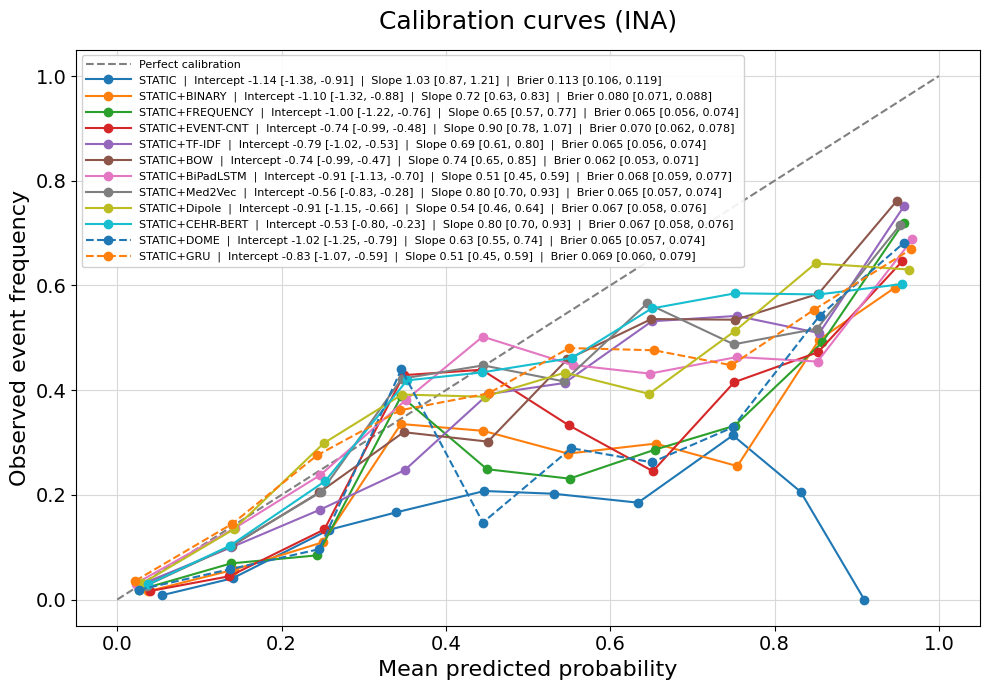

In [8]:
import pandas as pd
from scripts.plotting import plot_calibration_curves

summaries = {}
curves = {}
bands = {}
for m in methods.split(" "):
    calibration = pd.read_csv(f"{results_dir}/calibration_{dataset}_{m}_ITER{iter}.csv")
    summaries[m] = pd.read_csv(f"{results_dir}/summary_{dataset}_{m}_ITER{iter}.csv",index_col=0,)
    x = calibration["prob_pred"].to_numpy()
    curves[m] = (x,calibration["prob_true"].to_numpy(),)
    bands[m] = (x,calibration["ci95_low"].to_numpy(),calibration["ci95_high"].to_numpy(),)
    
fig, ax = plot_calibration_curves(
    methods=methods.split(' '),
    summary=summaries,
    curves=curves,
    dataset=dataset,
    bands=bands,
    figsize=(10, 7),
    legend_fontsize=8,
    show_ci_band=False,
)

## Radar plot

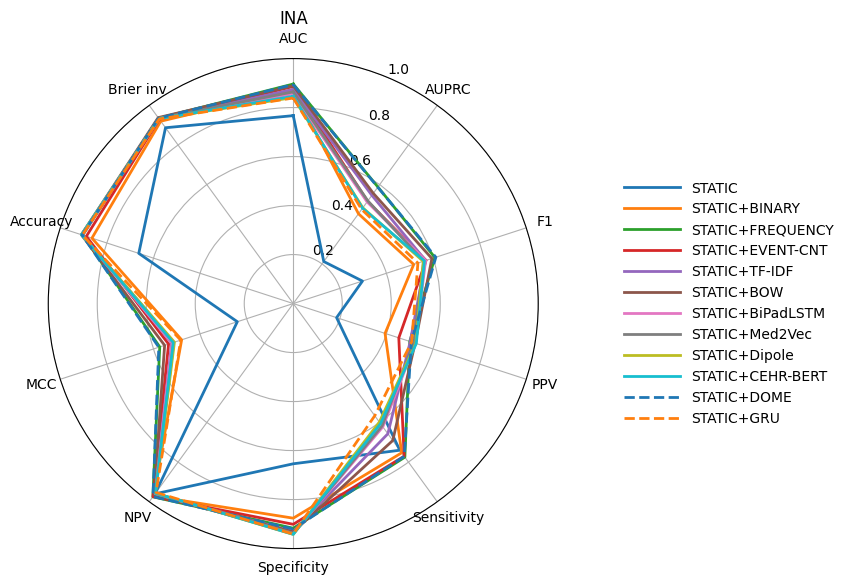

(<Figure size 1000x700 with 1 Axes>, <PolarAxes: title={'center': 'INA'}>)

In [7]:
from scripts.plotting import plot_radar
import pandas as pd
table = pd.read_csv(f"{results_dir}/result_table_{dataset}_ITER{iter}.csv",index_col=0,).drop(columns=['Confusion matrix']).apply(lambda col: col.str[0:5])
table['Brier inv'] = table['Brier'].apply(lambda x: f"{1-float(x)}")
table.drop(columns=['Brier', 'Intercept', 'Slope'], inplace=True)
plot_radar(table,title=f"{dataset}")

## Statistical Analysis

In [6]:
import pickle
import pandas as pd
from scripts.stats import stats_analysis
# Load results
meths = methods.split(' ')
meths.remove('STATIC')
results = {m: {} for m in meths}
for i in range(iter):
    for m in meths:
        meth = m.replace('+','_')
        path = (f"{results_dir}/results_{dataset}_{meth}_ITER{i}.pkl")
        with open(path, "rb") as f:
            results[m][i] = pickle.load(f)
friedman_df, ranking_table = stats_analysis(results, metrics, meths, iter)
friedman_df["p_value"] = pd.to_numeric(friedman_df["p_value"], errors="raise").astype(float)
display(friedman_df)
display(ranking_table)


=== FRIEDMAN TEST ===
Statistic: 187.0404
p-value: 8.07e-35
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 143.1452
p-value: 9.55e-26
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 110.5838
p-value: 4.07e-19
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 134.7127
p-value: 5.09e-24
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 248.4346
p-value: 1.16e-47
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 214.1934
p-value: 1.75e-40
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 228.2941
p-value: 1.96e-43
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 112.0849
p-value: 2.03e-19
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 137.8194
p-value: 1.18e-24
➡️ SIGNIFICANT global differences


,statistic,p_value,global_diff
AUC,187.040408,8.070020e-35,YES
AUPRC,143.145249,9.545261e-26,YES
F1,110.583782,4.068650e-19,YES
PPV,134.712707,5.093075e-24,YES
Sensitivity,248.434635,1.158027e-47,YES
Specificity,214.1934,1.752905e-40,YES
NPV,228.29415,1.956836e-43,YES
MCC,112.084928,2.025201e-19,YES
Accuracy,137.819396,1.178637e-24,YES


,AUC,AUPRC,F1,PPV,Sensitivity,Specificity,NPV,MCC,Accuracy
STATIC+DOME,1,1,1,1,1,8,1,1,1
STATIC+FREQUENCY,1,2,1,1,1,8,1,1,1
STATIC+EVENT-CNT,3,4,4,10,1,10,1,4,10
STATIC+BOW,4,3,3,1,5,2,5,3,1
STATIC+TF-IDF,5,5,8,1,6,7,6,6,1
STATIC+BINARY,5,10,11,11,4,11,4,11,11
STATIC+Med2Vec,7,5,4,1,8,2,8,6,1
STATIC+BiPadLSTM,8,7,4,1,7,2,6,5,1
STATIC+Dipole,9,8,9,1,8,2,8,6,1
STATIC+CEHR-BERT,10,9,4,1,8,1,8,9,1


In [38]:
friedman_latex = friedman_df.copy()
friedman_latex["p_value"] = friedman_latex["p_value"].apply(
    lambda x: f"{x:.2e}"
)
friedman_latex["global_diff"] = friedman_latex["global_diff"].map({
    "YES": r"\checkmark",
    "NO": r"\ding{55}"
})
friedman_latex = friedman_latex.rename(columns={
    "statistic": "Statistic",
    "p_value": "$p$-value",
    "global_diff": "Difference"
})
friedman_latex = friedman_latex.T
latex_table = friedman_latex.T.to_latex(
    escape=False,
    caption="Friedman test results for all evaluation metrics.",
    label="tab:friedman",
    column_format="l" + "c"*len(friedman_latex.T.columns)
)
print(latex_table)

\begin{table}
\caption{Friedman test results for all evaluation metrics.}
\label{tab:friedman}
\begin{tabular}{lccc}
\toprule
 & Statistic & $p$-value & Difference \\
\midrule
AUC & 207.663211 & 4.06e-39 & \checkmark \\
AUPRC & 175.289143 & 2.22e-32 & \checkmark \\
F1 & 111.599628 & 2.54e-19 & \checkmark \\
PPV & 19.443325 & 3.50e-02 & \checkmark \\
Sensitivity & 166.427301 & 1.52e-30 & \checkmark \\
Specificity & 128.834276 & 8.08e-23 & \checkmark \\
NPV & 134.143757 & 6.66e-24 & \checkmark \\
MCC & 81.866837 & 2.16e-13 & \checkmark \\
Accuracy & 62.326751 & 1.31e-09 & \checkmark \\
\bottomrule
\end{tabular}
\end{table}



In [39]:
print(ranking_table.drop(columns=['AUPRC', 'PPV', 'NPV', 'Accuracy']).to_latex())

\begin{tabular}{lrrrrr}
\toprule
 & AUC & F1 & Sensitivity & Specificity & MCC \\
\midrule
STATIC+EVENT-CNT & 1 & 1 & 1 & 11 & 1 \\
STATIC+DOME & 1 & 2 & 2 & 6 & 2 \\
STATIC+BINARY & 1 & 2 & 2 & 8 & 3 \\
STATIC+FREQUENCY & 1 & 4 & 4 & 6 & 4 \\
STATIC+TF-IDF & 5 & 7 & 6 & 8 & 8 \\
STATIC+BiPadLSTM & 6 & 5 & 4 & 8 & 6 \\
STATIC+BOW & 6 & 11 & 10 & 2 & 11 \\
STATIC+CEHR-BERT & 8 & 9 & 9 & 4 & 8 \\
STATIC+Med2Vec & 8 & 10 & 10 & 1 & 8 \\
STATIC+Dipole & 8 & 6 & 6 & 2 & 5 \\
STATIC+GRU & 11 & 7 & 8 & 5 & 7 \\
\bottomrule
\end{tabular}



## Memory/Time consumptions

In [5]:
import pandas as pd
from scripts.utils import highlight_best_values
df = pd.read_csv(f"{results_dir}/perf_{dataset}_ITER{iter}.csv", index_col=0)
df

,emb_train_time_s,emb_inference_time_s,emb_inference_ms_per_patient,emb_cpu_memory_delta_mb,emb_peak_gpu_memory_mb,emb_n_trainable_params,emb_n_total_params,clf_train_time_s,clf_inference_time_s,clf_inference_ms_per_patient,clf_cpu_memory_delta_mb
STATIC,nan±nan,nan±nan,nan±nan,nan±nan,nan±nan,nan±nan,nan±nan,0.175±0.099,0.001±0.000,0.003±0.001,0.138±2.351
BINARY,0.048±0.003,0.003±0.000,0.003±0.000,1707.772±353.103,nan±nan,379.000±0.000,nan±nan,0.131±0.066,0.001±0.000,0.003±0.000,0.077±0.435
FREQUENCY,0.047±0.004,0.001±0.000,0.001±0.000,1709.114±351.704,nan±nan,379.000±0.000,nan±nan,0.148±0.060,0.001±0.000,0.003±0.001,0.002±0.015
EVENT-CNT,0.008±0.001,0.000±0.000,0.000±0.000,1708.635±351.457,nan±nan,8.000±0.000,nan±nan,0.117±0.056,0.000±0.000,0.002±0.000,0.000±0.000
TF-IDF,0.074±0.051,0.010±0.001,0.007±0.001,1720.899±314.707,57.600±19.200,22108.020±569.876,22108.020±569.876,0.152±0.049,0.001±0.000,0.002±0.000,0.304±2.059
BOW,0.061±0.035,0.008±0.000,0.006±0.000,1721.585±312.650,57.600±19.200,21936.640±565.459,21936.640±565.459,0.148±0.046,0.001±0.000,0.002±0.000,0.004±0.016
BiPadLSTM,2.720±0.193,0.103±0.006,0.077±0.005,123.296±2.018,123.296±2.018,1081113.000±0.000,1081113.000±0.000,0.340±0.110,0.001±0.000,0.004±0.000,1.141±7.775
Med2Vec,6.727±0.370,0.032±0.003,0.024±0.002,1797.781±86.656,76.599±0.320,201592.000±0.000,201592.000±0.000,0.189±0.062,0.001±0.000,0.003±0.000,0.000±0.000
Dipole,2.274±0.131,0.116±0.025,0.086±0.019,1804.291±67.900,143.556±1.358,1185299.000±0.000,1185299.000±0.000,0.302±0.092,0.001±0.000,0.004±0.000,0.054±0.197
CEHR-BERT,3.228±0.167,0.158±0.011,0.118±0.008,1822.656±13.895,119.566±1.892,920762.000±0.000,920762.000±0.000,0.136±0.043,0.001±0.000,0.002±0.000,0.000±0.000
